# 01 – Glaciers SGI2023 dans la zone d'étude

Combien de glaciers du SGI2023 recoupent le massif Mischabel–Weisshorn, et de quelle taille sont-ils ?

In [1]:
from pathlib import Path

import geopandas as gpd
from shapely.geometry import box

# Racine du projet : les chemins sont relatifs à elle (le notebook tourne depuis notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

In [2]:
sgi = gpd.read_file(ROOT / "data/raw/sgi2023/SGI_2023_glaciers.shp")
print("CRS :", sgi.crs)

CRS : EPSG:2056


In [3]:
# Emprise en WGS84 -> reprojetée en LV95
zone = gpd.GeoDataFrame(geometry=[box(7.6, 46.0, 7.95, 46.15)], crs=4326).to_crs(2056)

inter = sgi[sgi.intersects(zone.geometry[0])]
dedans = sgi[sgi.within(zone.geometry[0])]
print("Intersectent :", len(inter), "| Entièrement dedans :", len(dedans))

Intersectent : 113 | Entièrement dedans : 97


In [4]:
inter = inter.assign(area_km2=inter.area / 1e6)
print(inter["area_km2"].describe())
print("< 0,5 km² :", (inter["area_km2"] < 0.5).sum())

count    113.000000
mean       1.380334
std        2.870400
min        0.011373
25%        0.056119
50%        0.238809
75%        1.153205
max       13.695879
Name: area_km2, dtype: float64
< 0,5 km² : 70


In [5]:
# Glaciers de référence (le nom de colonne peut varier : name, glacier_name...)
print(inter.columns.tolist())

['gid', 'pk_glacier', 'sgi-id', 'name', 'rl_3', 'rl_2', 'rl_1', 'rl_0', 'i_code', 'year_acq', 'year_rel', 'area_km2', 'length_km', 'masl_min', 'masl_med', 'masl_mean', 'masl_max', 'slope_deg', 'aspect_deg', 'geometry']


## Carte des glaciers de la zone

Fond : ombrage calculé sur swissALTI3D, rééchantillonné à 20 m pour l'affichage.

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import rasterio
from rasterio.merge import merge

# Mosaïque des dalles swissALTI3D à 20 m (suffisant pour un fond de carte)
tuiles = [rasterio.open(f) for f in sorted((ROOT / "data/raw/swissalti3d").glob("*.tif"))]
# Les zones sans dalle (hors emprise) reçoivent NaN pour ne pas apparaître en gris uni
mnt, transform = merge(tuiles, res=20, nodata=np.nan)
for t in tuiles:
    t.close()
mnt = mnt[0]


def ombrage(z, res, azimut=315, hauteur=45):
    """Ombrage classique (soleil au nord-ouest, 45° au-dessus de l'horizon)."""
    dy, dx = np.gradient(z, res)
    pente = np.arctan(np.hypot(dx, dy))
    aspect = np.arctan2(-dx, dy)
    az, h = np.radians(azimut), np.radians(hauteur)
    return np.sin(h) * np.cos(pente) + np.cos(h) * np.sin(pente) * np.cos(az - aspect)


ombre = ombrage(mnt, 20)
emprise_mnt = (transform.c, transform.c + transform.a * mnt.shape[1],
               transform.f + transform.e * mnt.shape[0], transform.f)

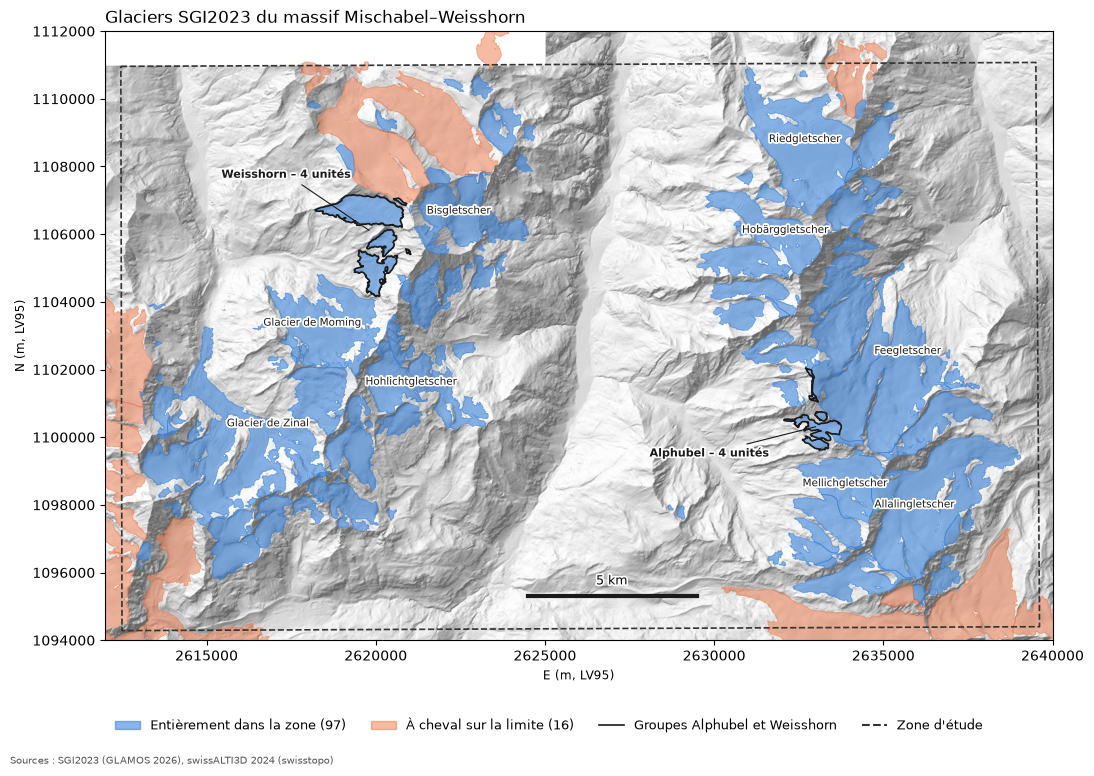

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

BLEU, ORANGE, ENCRE = "#2a78d6", "#eb6834", "#1a1a1a"
halo = [pe.withStroke(linewidth=2.5, foreground="white")]
a_cheval = inter[~inter.index.isin(dedans.index)]

# Étiquettes simples : les grands glaciers entièrement dans la zone
grands = dedans[dedans["area_km2"] > 2.5]

# Groupes clés pour l'étude : contour sombre et une seule étiquette par groupe, décalée
groupes = {
    "Alphubel": ("Alphubel", (-3200, -900)),
    "Weisshorn": ("Weisshorn", (-2500, 1600)),
}

fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(ombre, cmap="gray", extent=emprise_mnt, vmin=-0.2, vmax=1, alpha=0.6)
dedans.plot(ax=ax, color=BLEU, alpha=0.55, edgecolor=BLEU, linewidth=0.6)
a_cheval.plot(ax=ax, color=ORANGE, alpha=0.45, edgecolor=ORANGE, linewidth=0.6)
zone.boundary.plot(ax=ax, color="#333333", linewidth=1.2, linestyle="--")

for _, g in grands.iterrows():
    p = g.geometry.representative_point()
    ax.annotate(g["name"], (p.x, p.y), fontsize=7.5, ha="center", color=ENCRE, path_effects=halo)

for etiquette, (motif, (dx, dy)) in groupes.items():
    sel = dedans[dedans["name"].str.contains(motif)]
    sel.boundary.plot(ax=ax, color=ENCRE, linewidth=1.2)
    c = sel.union_all().centroid
    ax.annotate(f"{etiquette} – {len(sel)} unités", (c.x, c.y), xytext=(c.x + dx, c.y + dy),
                fontsize=8, fontweight="bold", ha="center", color=ENCRE, path_effects=halo,
                arrowprops=dict(arrowstyle="-", color=ENCRE, linewidth=0.8))

# Barre d'échelle de 5 km, dans la vallée de Zermatt–Saas (zone sans glacier)
x0, y0 = 2624500, 1095300
ax.plot([x0, x0 + 5000], [y0, y0], color=ENCRE, linewidth=3)
ax.text(x0 + 2500, y0 + 350, "5 km", ha="center", fontsize=9, path_effects=halo)

ax.set_xlim(emprise_mnt[0], emprise_mnt[1])
ax.set_ylim(emprise_mnt[2], emprise_mnt[3])
ax.set_xlabel("E (m, LV95)")
ax.set_ylabel("N (m, LV95)")
ax.ticklabel_format(style="plain")
ax.set_title("Glaciers SGI2023 du massif Mischabel–Weisshorn", loc="left")

# Légende sous la carte pour ne masquer aucun glacier
fig.legend(handles=[
    Patch(color=BLEU, alpha=0.55, label=f"Entièrement dans la zone ({len(dedans)})"),
    Patch(color=ORANGE, alpha=0.45, label=f"À cheval sur la limite ({len(a_cheval)})"),
    Line2D([], [], color=ENCRE, linewidth=1.2, label="Groupes Alphubel et Weisshorn"),
    Line2D([], [], color="#333333", linestyle="--", label="Zone d'étude"),
], loc="lower center", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0.03))
fig.text(0.01, 0.005, "Sources : SGI2023 (GLAMOS 2026), swissALTI3D 2024 (swisstopo)",
         fontsize=7, color="#555555")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(ROOT / "figures/01_carte_glaciers_zone.png", dpi=200)
plt.show()